# 02 · Métricas de detecção e resultados

In [1]:
import sys, json, glob, pickle
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, matplotlib
matplotlib.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
import matplotlib.pyplot as plt


## 1. As métricas num exemplo que dá para conferir à mão
Duas verdades, três predições (0,9 acerta · 0,8 erra · 0,7 acerta).

In [2]:
from weedvision import metrics as M
g = [np.array([[0,0,0,10,10],[0,50,50,60,60]])]
p = [np.array([[0,.9,0,0,10,10],[0,.8,100,100,110,110],[0,.7,50,50,60,60]])]
rec, prec, _ = M.pr_curve(g, p, 0); print("revocação", rec, "precisão", prec.round(3))
print("AP50 =", round(M.average_precision(g, p, 0), 4), "(esperado (51·1 + 50·2/3)/101 = %.4f)" % ((51+50*2/3)/101))

revocação [0.5 0.5 1. ] precisão [1.    0.5   0.667]
AP50 = 0.835 (esperado (51·1 + 50·2/3)/101 = 0.8350)


## 2. Conferência com pycocotools (implementação independente)

In [3]:
import importlib.util, sys
sys.path.insert(0, str(ROOT/"tests"))
from test_metrics import _random_dataset, _coco_ap
for seed in range(3):
    gts, preds, shapes = _random_dataset(seed)
    ref = _coco_ap(gts, preds, 2, shapes)
    print(seed, [(round(M.average_precision(gts, preds, c, .5), 4), round(ref[c][0], 4)) for c in range(2)], "(próprio, pycocotools)")

creating index...
index created!
Loading and preparing results...
DONE (t=0.00s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.00s).
Accumulating evaluation results...
DONE (t=0.00s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.252
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.559
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.183
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.000
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.263
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.736
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.180
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.395
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.395
 Average Recall     (AR) @[ IoU=0.5

**Leitura:** os APs da implementação própria batem com o `pycocotools` (os pares impressos coincidem), em linha com os testes automatizados (tolerância 2·10⁻³). Isso valida o *cálculo*, não os modelos.

## 3. Resultados dos modelos (lidos de `runs/eval`)

In [4]:
import pandas as pd
rows = []
for f in sorted((ROOT/"runs/eval").glob("*.json")):
    r = json.load(open(f)); w = r["prf"]["weed"]
    rows.append({"modelo": r["model"], "conjunto": r["split"]+" ("+r["dataset"]+")", "imgs": r["n_images"], "mAP50": r["map50"], "mAP50-95": r["map50_95"], "P@.25": w["precision"], "R@.25": w["recall"], "F1@.25": w["f1"]})
df = pd.DataFrame(rows).round(3); pd.set_option("display.width", 200); print(df.to_string(index=False))

                modelo                  conjunto  imgs  mAP50  mAP50-95  P@.25  R@.25  F1@.25
            frcnn_mnv3        test (sudars_weed)   134  0.612     0.326  0.543  0.684   0.605
            frcnn_mnv3 test_origin (sudars_weed)   241  0.186     0.070  0.349  0.244   0.287
            frcnn_mnv3         val (sudars_weed)   151  0.709     0.323  0.612  0.760   0.678
   frcnn_mnv3_on_maize         test (maize_test)   500  0.000     0.000    NaN  0.000     NaN
         frcnn_mnv3_v2        test (sudars_weed)   134  0.605     0.317  0.525  0.675   0.591
         frcnn_mnv3_v2 test_origin (sudars_weed)   241  0.179     0.063  0.343  0.251   0.290
         frcnn_mnv3_v2         val (sudars_weed)   151  0.689     0.312  0.581  0.744   0.653
frcnn_mnv3_v2_on_maize         test (maize_test)   500  0.000     0.000    NaN  0.000     NaN
               yolo11n        test (sudars_weed)   134  0.725     0.488  0.653  0.752   0.699
               yolo11n test_origin (sudars_weed)   241  0.29

**Leitura:** YOLO11n e 11s empatam no mesmo domínio (mAP50 ≈ 0,72 no teste); o Faster R-CNN MobileNetV3 fica abaixo (≈ 0,61) com a receita usada; **todos** caem muito no grupo `IMG_*` (0,18–0,29) e zeram no milho (a precisão é `NaN` porque nenhuma caixa passa de 0,25: sem predições, precisão é indefinida). As linhas `_onnx` repetem os YOLO exportados.

## 4. Curvas PR e matriz de confusão (YOLO11n)

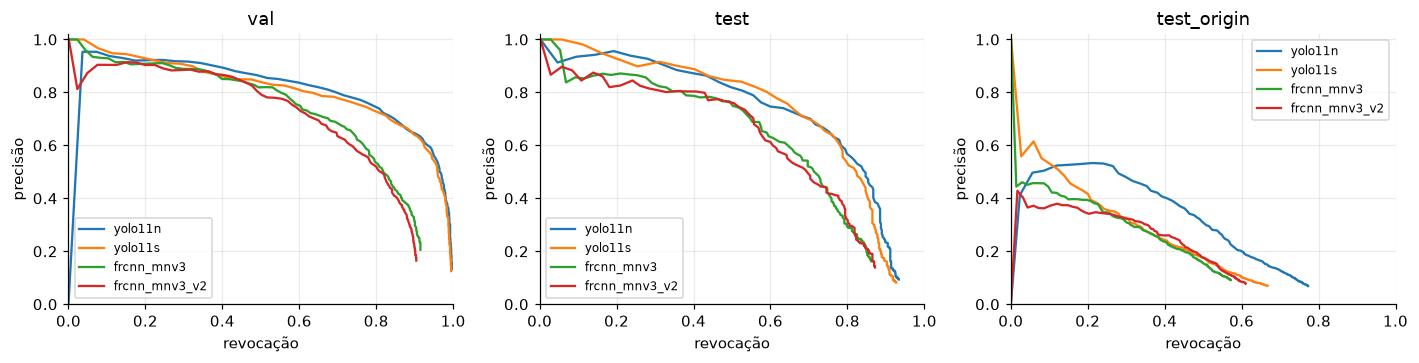

confusão YOLO11n/test (linhas=predito, colunas=real; último índice = fundo):
 [[340 181]
 [112   0]]


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for k, s in enumerate(("val", "test", "test_origin")):
    for m in ("yolo11n", "yolo11s", "frcnn_mnv3", "frcnn_mnv3_v2"):
        f = ROOT/f"runs/eval/{m}__{s}.json"
        if f.exists():
            c = json.load(open(f))["pr_curves"]["weed"]; ax[k].plot(c["recall"], c["precision"], label=m)
    ax[k].set_title(s); ax[k].set_xlabel("revocação"); ax[k].set_ylabel("precisão"); ax[k].set_xlim(0, 1); ax[k].set_ylim(0, 1.02); ax[k].legend(fontsize=8)
plt.tight_layout(); plt.show()
cm = np.array(json.load(open(ROOT/"runs/eval/yolo11n__test.json"))["confusion_matrix"])
print("confusão YOLO11n/test (linhas=predito, colunas=real; último índice = fundo):\n", cm)

**Leitura:** as curvas do YOLO ficam acima do Faster R-CNN em quase toda a faixa de revocação no val e no teste; no `test_origin` todas colapsam cedo (revocação máxima baixa). Na matriz do YOLO11n/teste: 340 acertos, 181 falsos positivos (coluna 'fundo') e 112 falsos negativos (linha 'fundo'); com uma só classe não há confusão entre classes.

## 5. Falsos negativos: por tamanho e por motivo

In [6]:
for m in ("yolo11n", "frcnn_mnv3_v2"):
    for s in ("test", "test_origin"):
        f = ROOT/f"runs/eval/{m}__{s}.json"
        if not f.exists(): continue
        fn = json.load(open(f))["false_negatives"]; print(f"\n{m} / {s}: {fn['fn_total']}/{fn['n_gt']} FN | motivos {fn['motivos']}")
        for k, v in fn["por_tamanho"].items(): print(f"   {k:34s} n={v['n']:4d} FN={v['fn']:4d} taxa={v['taxa_fn']:.2f}" if v["taxa_fn"] is not None else f"   {k} n=0")


yolo11n / test: 112/452 FN | motivos {'classe_errada': 0, 'localizacao_ruim': 1, 'ausente': 111}
   muito pequeno (<0,05% da imagem)   n=  28 FN=  11 taxa=0.39
   pequeno (0,05–0,1%)                n=  98 FN=  18 taxa=0.18
   médio (0,1–0,25%)                  n= 189 FN=  50 taxa=0.26
   grande (≥0,25%)                    n= 137 FN=  33 taxa=0.24

yolo11n / test_origin: 944/1401 FN | motivos {'classe_errada': 0, 'localizacao_ruim': 43, 'ausente': 901}
   muito pequeno (<0,05% da imagem)   n= 169 FN=  93 taxa=0.55
   pequeno (0,05–0,1%)                n= 490 FN= 346 taxa=0.71
   médio (0,1–0,25%)                  n= 431 FN= 338 taxa=0.78
   grande (≥0,25%)                    n= 311 FN= 167 taxa=0.54

frcnn_mnv3_v2 / test: 147/452 FN | motivos {'classe_errada': 0, 'localizacao_ruim': 8, 'ausente': 139}
   muito pequeno (<0,05% da imagem)   n=  28 FN=  12 taxa=0.43
   pequeno (0,05–0,1%)                n=  98 FN=  31 taxa=0.32
   médio (0,1–0,25%)                  n= 189 FN=  63 taxa=0.3

**Leitura:** no teste os FN não crescem de forma regular com o tamanho e quase todos são 'ausente' (o modelo não propõe nada). No `test_origin` a taxa é alta em todos os tamanhos (YOLO11n 54–78%; Faster R-CNN v2 51–88%) e não-monotônica → problema de **domínio**, não de tamanho.

## 6. Incerteza: bootstrap por imagem (IC 95%) e diferença pareada

In [7]:
b = json.load(open(ROOT/"runs/bootstrap.json"))
for s, d in b.items():
    print(f"\n{s} (n={d['n_images']} imagens)")
    for m, r in d.items():
        if isinstance(r, dict) and "map50" in r:
            line = f"  {m:14s} mAP50 {r['map50']['media']:.3f} IC95 [{r['map50']['ic95'][0]:.3f}, {r['map50']['ic95'][1]:.3f}]"
            for k, v in r.items():
                if k.startswith("diferenca"): line += f" | Δ vs base {v['map50']['media']:+.3f} [{v['map50']['ic95'][0]:+.3f}, {v['map50']['ic95'][1]:+.3f}]"
            print(line)


val (n=151 imagens)
  yolo11n        mAP50 0.822 IC95 [0.796, 0.847]
  yolo11s        mAP50 0.811 IC95 [0.783, 0.838] | Δ vs base -0.011 [-0.027, +0.004]
  frcnn_mnv3_v2  mAP50 0.689 IC95 [0.654, 0.727] | Δ vs base -0.133 [-0.156, -0.112]

test (n=134 imagens)
  yolo11n        mAP50 0.724 IC95 [0.668, 0.778]
  yolo11s        mAP50 0.728 IC95 [0.665, 0.786] | Δ vs base +0.003 [-0.027, +0.030]
  frcnn_mnv3_v2  mAP50 0.604 IC95 [0.539, 0.667] | Δ vs base -0.121 [-0.154, -0.088]

test_origin (n=241 imagens)
  yolo11n        mAP50 0.298 IC95 [0.249, 0.343]
  yolo11s        mAP50 0.220 IC95 [0.173, 0.274] | Δ vs base -0.078 [-0.105, -0.047]
  frcnn_mnv3_v2  mAP50 0.184 IC95 [0.148, 0.216] | Δ vs base -0.114 [-0.154, -0.070]


**Leitura:** YOLO11n vs 11s: diferença **indistinguível** no val e no teste (IC inclui 0); no `test_origin` o 11s é pior (≈ −0,08). Faster R-CNN v2 fica abaixo dos dois (IC da diferença não inclui 0). **Ressalva:** os ICs ignoram a correlação entre quadros da mesma sessão e há uma só semente — são otimistas.